# DATA-445: Homework Assignment 7

**Instructions**

- This homework assignment is worth **103** points.
- Please submit a **.ipynb** file to Blackboard.
- **Please strive for clarity and organization.**
- **AI usage**:
  - AI use is strictly **prohibited** for conceptual exercises.
  - For applied (Python) exercises, you may use AI exclusively for **debugging**. Do not use AI to generate answers.
- **Due Date: November 6, 2026, by 11:59 PM.**

## Exercise 1 (5 points)

Why feature scaling is important for the $k$-means algorithm? Be specific.

**Answer:** - Feature scaling is important for K-Means since the algorithm uses distance to group similar points. If one has larger values than others, it can dominate distance calculations and cause the clusters to be based more on that feature. 

## Exercise 2 (5 points)

How can clustering be used to improve the performance of a linear model?

(a) Creating different models for different cluster groups.

(b) Creating an input feature for cluster ids as dummy variables.

(c) Creating an input feature for cluster centroids as a continuous variable.

(d) Creating an input feature for cluster size as a continuous variable.

(e) All of the above.

(f) None of the above.

**Answer:** - I think the answer is (e) all of the above. 

## Exercise 3 (5 points)

What are the risks of initial random cluster centroids assignments in $k$-means? Be specific.

**Answer:** - Initial random cluster centroid assignments cause K-Means to produce inconsistent clusters, since the starting points affect the result. The model might converge to a specific minimum instead of the best solution.

## Exercise 4 (5 points)

Spectral clustering and $k$-means make different assumptions about the shape of the clusters. Explain, in your own words, how spectral clustering constructs clusters (mention the similarity graph and the graph Laplacian) and describe a type of dataset for which spectral clustering would be expected to outperform $k$-means. Be specific.

**Answer:** - Spectral clustering creates similar graphs where each data point is a node and connections between similar points are edges. After it utilizes the graph Laplacian so it can understand the connections between points and identify groups that are strongly connected. Spectral clustering outperforms K-Means on irregularly shaped datasets.

## Exercise 5 (5 points)

In $k$-means, every observation is assigned to exactly one cluster (a hard assignment). Explain how fuzzy c-means differs from $k$-means in terms of cluster membership, and describe what role the fuzziness parameter $m$ plays in the algorithm. Be specific.

**Answer:** - Fuzzy C-Means is different from K-Means because it allows every observation to belong to multiple clusters with different membership percentages instead of assigning it to one cluster. The parameter m controls how spread out the memberships are. Closer to 1 is harder assignments and anything larger than 1 creates overlap between clusters. Most common value for m is 2. 

## Exercise 6

Consider the `Mall_Customers.csv` data file. This file contains the basic information (ID, age, gender, income, spending score) about mall customers in the US. **In Python**, answer the following:

### (a) (5 points)

Using the `pandas` library, read the csv data file and create a data-frame called `customers`. Remove the observations with missing values (if there are missing values).

In [49]:
# Your code here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (calinski_harabasz_score, davies_bouldin_score, silhouette_score)

customers = pd.read_csv("Mall_Customers.csv")
customers = customers.dropna().reset_index(drop=True)
customers.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### (b) (8 points)

Using the appropriate Python commands, put `Gender`, `Age` and `Annual Income (k$)` in the same scale.

In [50]:
# Your code here

customers["Gender"] = customers["Gender"].map({"Male": 0, "Female": 1})

features = ["Gender", "Age", "Annual Income (k$)"]
scaler = MinMaxScaler()
X = scaler.fit_transform(customers[features])

### (c) (30 points)

Because you are not familiar enough with buying patterns in malls, estimate the number of clusters for this dataset using the Calinski-Harabasz, Davies-Bouldin, and Silhouette scores. Do the following:

- Using `Gender`, `Age` and `Annual Income (k$)` cluster that data into clusters ($k = 2, 3, \ldots, 9, 10$). Use `n_init = 20`.
- For each clustering result, compute the Calinski-Harabasz, Davies-Bouldin, and Silhouette scores.
- Visualize the Calinski-Harabasz, Davies-Bouldin, and Silhouette scores.
- Estimate the number of clusters.

c:\Users\15154\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\15154\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\15154\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\15154\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Window

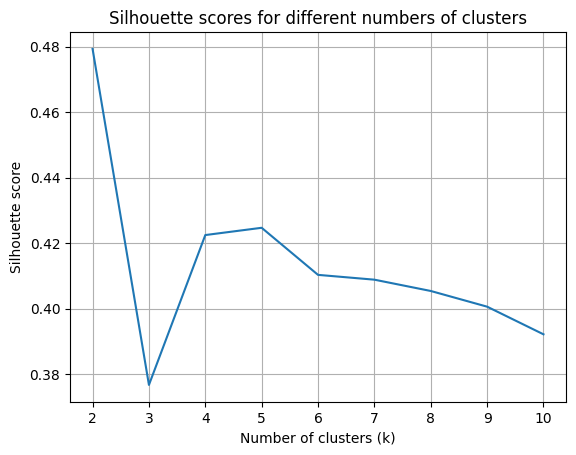

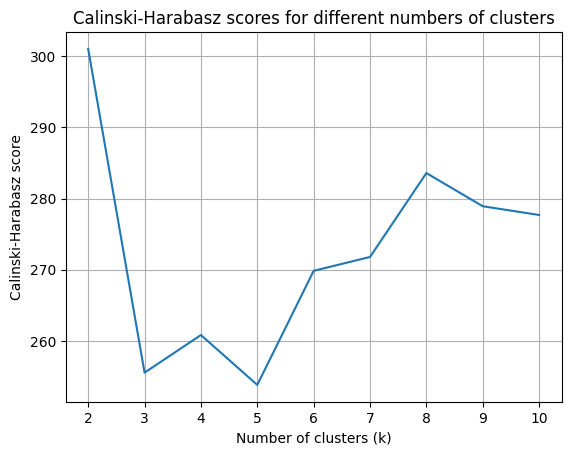

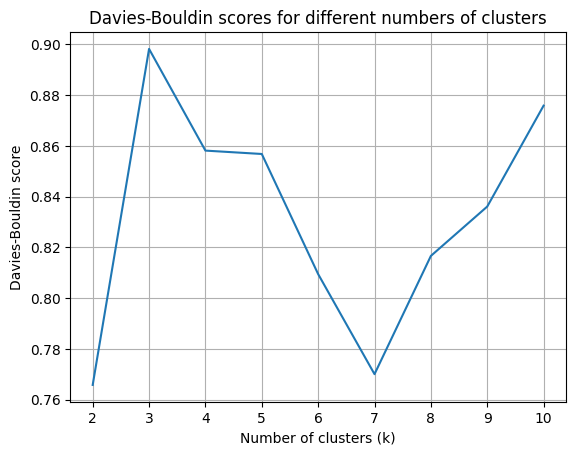

Calinski-Harabasz Index: 225.65339061736174
Davies-Bouldin Index: 0.7695251906660606
Silhouette Score: 0.4331549993604238


In [51]:
# your code here
components_scaled = customers[features]

kmeans = KMeans(n_clusters=4, n_init = 20, random_state=42)
kmeans.fit(components_scaled)
labels = kmeans.labels_

sil_score = []
ch_score = []
db_score = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    kmeans.fit(customers)
    sil_score.append(silhouette_score(customers, kmeans.labels_))
    ch_score.append(calinski_harabasz_score(customers, kmeans.labels_))
    db_score.append(davies_bouldin_score(customers, kmeans.labels_))

plt.plot(range(2, 11), sil_score)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette scores for different numbers of clusters")
plt.grid(True)
plt.show()

plt.plot(range(2, 11), ch_score)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Calinski-Harabasz score")
plt.title("Calinski-Harabasz scores for different numbers of clusters")
plt.grid(True)
plt.show()

plt.plot(range(2, 11), db_score)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Davies-Bouldin score")
plt.title("Davies-Bouldin scores for different numbers of clusters")
plt.grid(True)
plt.show()

print("Calinski-Harabasz Index:", calinski_harabasz_score(components_scaled, labels))
print("Davies-Bouldin Index:", davies_bouldin_score(components_scaled, labels))
print("Silhouette Score:", silhouette_score(components_scaled, labels))

### (d) (8 points)

Using the results from part (c), cluster the data into that number of clusters (use `n_init = 20`).

In [52]:
# Your code here
k_best = 2

final = KMeans(n_clusters=k_best, n_init=20, random_state=42)
customers["Cluster"] = final.fit_predict(X)


c:\Users\15154\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


### (e) (7 points)

Describe each of the clusters. Does the clustering results make sense? If not, suggest how you would improve this analysis.

In [53]:
# Your code here
summary = customers.groupby("Cluster")[features].agg(["mean", "count"])
print(summary)
print(customers.groupby("Cluster")[["Age", "Annual Income (k$)","Gender"]].mean())

        Gender              Age       Annual Income (k$)      
          mean count       mean count               mean count
Cluster                                                       
0          0.0    88  39.806818    88          62.227273    88
1          1.0   112  38.098214   112          59.250000   112
               Age  Annual Income (k$)  Gender
Cluster                                       
0        39.806818           62.227273     0.0
1        38.098214           59.250000     1.0


## Exercise 7 (20 points)

Consider again the `Mall_Customers.csv` data file. In this exercise you will use **DBSCAN** to find groups of customers based on `Annual Income (k$)` and `Spending Score (1-100)`, and to identify customers that do not belong to any group. **In Python**, answer the following:

### (a) (4 points)

Read the csv data file into a data-frame called `mall`, and standardize `Annual Income (k$)` and `Spending Score (1-100)` (mean 0 and standard deviation 1). Explain why scaling matters for DBSCAN.

In [54]:
# Your code here
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

mall = pd.read_csv('Mall_Customers.csv')
cols = ['Annual Income (k$)', 'Spending Score (1-100)']
X = MinMaxScaler().fit_transform(mall[cols])
mall.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### (b) (6 points)

Set `min_samples = 5`. Choose a value for `eps` using a $k$-distance plot: for each observation compute the distance to its 5th nearest neighbor (the observation itself counts as its own first neighbor in `sklearn`), sort these distances, and plot them. Which value of `eps` do you choose and why?

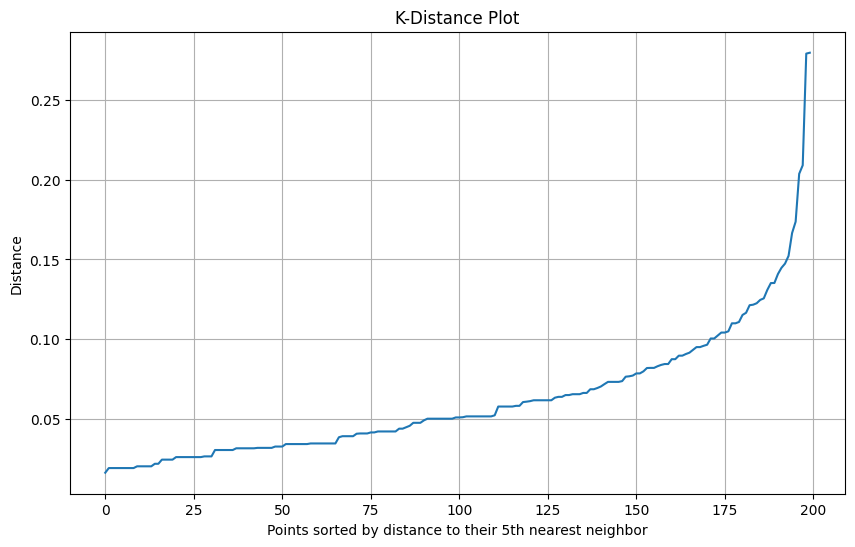

In [55]:
# your code here
min_samples = 5
distances, _ = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)
sorted_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 6))
plt.plot(sorted_distances)
plt.title('K-Distance Plot')
plt.xlabel('Points sorted by distance to their 5th nearest neighbor')
plt.ylabel('Distance')
plt.grid(True)
plt.show()

Answer: I would choose the EPS of 0.1, because that is where the k-distance curve bends sharply upward.

### (c) (5 points)

Fit DBSCAN with `min_samples = 5` and your chosen `eps`. Report the number of clusters found, the size of each cluster, and the number of observations labeled as noise. Then visualize the result with a scatter plot of the two variables, coloring the points by cluster label and showing noise points in a distinct color.

Clusters found: 3
cluster
-1     14
 0    142
 1     11
 2     33
Name: count, dtype: int64


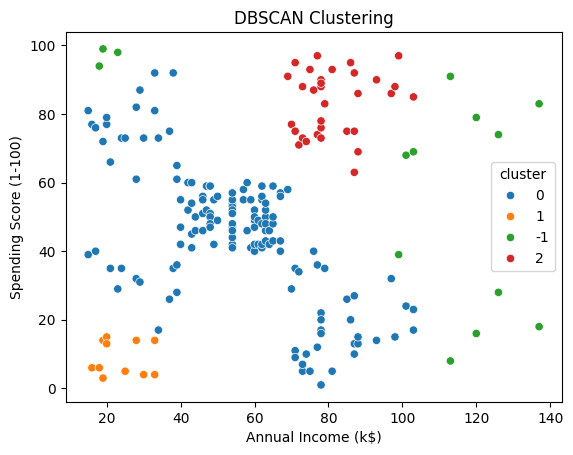

In [56]:
# your code here
eps = 0.1

mall['cluster'] = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)

print('Clusters found:', mall['cluster'].nunique() - (-1 in mall['cluster'].values))
print(mall['cluster'].value_counts().sort_index())   # sizes; -1 is noise

import seaborn as sns
sns.scatterplot(data=mall, x=cols[0], y=cols[1], hue=mall['cluster'].astype(str), palette='tab10')
plt.title('DBSCAN Clustering')
plt.show()

### (d) (5 points)

Describe each cluster (average income and spending score) and the noise points. Then explain what happens to the number of clusters and the number of noise points if you (i) decrease `eps` or (ii) increase `min_samples`. Support your answer by trying at least two different settings. How does DBSCAN compare to $k$-means for this data?

In [57]:
# Your code here
print(mall.groupby('cluster')[cols].mean())

labels1 = DBSCAN(eps=0.75 * eps, min_samples=min_samples).fit_predict(X)
n_clusters1 = len(set(labels1)) - (1 if -1 in labels1 else 0)
n_noise1 = (labels1 == -1).sum()

labels2 = DBSCAN(eps=eps, min_samples=2 * min_samples).fit_predict(X)
n_clusters2 = len(set(labels2)) - (1 if -1 in labels2 else 0)
n_noise2 = (labels2 == -1).sum()

print(f'Smaller eps: {n_clusters1} clusters, {n_noise1} noise points')
print(f'Larger min_samples: {n_clusters2} clusters, {n_noise2} noise points')

         Annual Income (k$)  Spending Score (1-100)
cluster                                            
-1                96.785714               61.714286
 0                55.077465               44.640845
 1                23.727273                8.909091
 2                81.060606               83.000000
Smaller eps: 6 clusters, 26 noise points
Larger min_samples: 4 clusters, 47 noise points


**Answer:** - If you keep shrinking eps, clusters start disappearing into noise and the cluster count can fall. If it takes more neighbors to be a core point, more points fail that test, so the noise count should go up.